### Main file

Imports the main libraries used throughout the notebook:
- `numpy` for numerical operations
- `pandas` for dataframe handling
- `torch` for deep learning


In [34]:
import numpy as np
import pandas as pd
import torch

Loads the compost dataset from `./dataset/waste_catalogue_completed.csv` and displays the first 10 rows using `head(10)`.

This gives the reader a quick view of the dataset structure before feature engineering begins.


In [35]:
compost = pd.read_csv('./dataset/waste_catalogue_completed.csv')

compost.head(10)

,id,food_name,food_category,food_category_code,moisture_min,moisture_max,moisture_midpoint,cn_ratio_min,cn_ratio_max,cn_ratio_midpoint,...,has_cn_estimate,waste_condition,primary_composition,degradation_rate_text,ai_sensor_considerations,compost_properties,crop_options_text,composting_notes,uncertainty_data_quality,cn_est_basis_assumption
0,1,White rice,"Cooked rice / grain dish (soft, moist)",6,62,72.0,67.0,30,45,37.5,...,1,"Cooked, as served or leftover. Record plain vs...",Gelatinised starch (~75â€“80% of dry matter) w...,"Fast (days) in a hot, aerated pile; large wet ...","Cooked-vs-dry state, oil sheen, sauce/colour (...",Readily degradable carbohydrate; low in N (hig...,"Hypothesis only: use after EC, maturity and N-...",Break up clumps; mix thin layers with dry brow...,Moisture is a typical cooked-food range; actua...,Dry-matter basis (water has no C or N). Protei...
1,2,Brown rice,"Cooked rice / grain dish (soft, moist)",6,62,72.0,67.0,25,40,32.5,...,1,"Cooked, as served or leftover. Record plain vs...",Gelatinised starch (~75â€“80% of dry matter) w...,"Fast (days) in a hot, aerated pile; large wet ...","Cooked-vs-dry state, oil sheen, sauce/colour (...",Readily degradable carbohydrate; low in N (hig...,"Hypothesis only: use after EC, maturity and N-...",Break up clumps; mix thin layers with dry brow...,Moisture is a typical cooked-food range; actua...,Dry-matter basis (water has no C or N). Protei...
2,3,Poha (flattened rice),"Cooked rice / grain dish (soft, moist)",6,55,70.0,62.5,25,40,32.5,...,1,"Cooked, as served or leftover. Record plain vs...",Gelatinised starch (~75â€“80% of dry matter) w...,"Fast (days) in a hot, aerated pile; large wet ...","Cooked-vs-dry state, oil sheen, sauce/colour (...",Readily degradable carbohydrate; low in N (hig...,"Hypothesis only: use after EC, maturity and N-...",Break up clumps; mix thin layers with dry brow...,Moisture is a typical cooked-food range; actua...,Dry-matter basis (water has no C or N). Protei...
3,4,Puffed rice (murmura),Dry grain / flour / flake / semolina (uncooked...,13,4,8.0,6.0,30,45,37.5,...,1,"Uncooked dry ingredient (spoiled, expired or s...",Starch (55â€“75%) with 7â€“13% protein and 1â€...,Medium; fine dry flour clumps and resists wett...,"Colour/texture (fine vs coarse), clumping, mou...",Carbon-rich with moderate N (wheat/millet) to ...,Hypothesis only (not food-specific): mature co...,Mix in small amounts; pre-moisten and blend wi...,Dry-ingredient state assumed. If the class is ...,Dry-matter basis (water has no C or N). Protei...
4,5,Rice flour,Dry grain / flour / flake / semolina (uncooked...,13,10,13.0,11.5,30,45,37.5,...,1,"Uncooked dry ingredient (spoiled, expired or s...",Starch (55â€“75%) with 7â€“13% protein and 1â€...,Medium; fine dry flour clumps and resists wett...,"Colour/texture (fine vs coarse), clumping, mou...",Carbon-rich with moderate N (wheat/millet) to ...,Hypothesis only (not food-specific): mature co...,Mix in small amounts; pre-moisten and blend wi...,Dry-ingredient state assumed. If the class is ...,Dry-matter basis (water has no C or N). Protei...
5,6,Idli,Steamed / griddled batter or dough item,24,55,68.0,61.5,20,35,27.5,...,1,"Steamed, griddled or fermented batter items, a...",Starch from rice/millet/pulse batter with 8â€“...,Fast; crisp or oily items and dense steamed ca...,Surface texture (porous steamed vs crisp gridd...,Readily degradable starch and some protein; ac...,"Hypothesis only: use after EC, maturity and N-...",Crumble and mix with dry browns; keep sauces/g...,Fermentation pH is an estimate from typical ba...,Dry-matter basis (water has no C or N). Protei...
6,7,Dosa,Steamed / griddled batter or dough item,24,40,60.0,50.0,20,35,27.5,...,1,"Steamed, griddled or fermented batter items, a...",Starch from rice/millet/pulse batter with 8â€“...,Fast; crisp or oily items and dense steamed ca...,Surface texture (porous steamed vs crisp gridd...,Readily degradable starch and some protein; ac...,"Hypothesis only: use after 

Creates the `common_drop` list, which contains columns to remove from all three model variants.

These are mostly identifiers, text fields, or demo/description columns that are not useful for numeric model training.

Then it creates the `range_drop` list and builds `compost_range` by dropping all range-irrelevant columns. The one-hot encoded version `compost_range_int` is created so categorical variables become numeric features.


In [36]:
# Common columns to drop from all three datasets
common_drop = [
    'id',
    'food_name',
    'moisture_band_demo',
    'cn_ratio_band_demo',
    'ph_band_demo',
    'food_category',
    'target_degradation_class_demo',
    'ai_sensor_considerations',
    'composting_notes',
    'uncertainty_data_quality',
    'degradation_rate_text'
]

# Model 1: Min/max ranges
range_drop = common_drop + [
    'moisture_midpoint',
    'cn_ratio_midpoint',
    'ph_midpoint',
    'moisture_band_code',
    'cn_ratio_band_code',
    'ph_band_code'
]

compost_range = compost.drop(range_drop, axis=1)
compost_range_int = pd.get_dummies(compost_range, dtype=int)

compost_range_int.head()

,food_category_code,moisture_min,moisture_max,cn_ratio_min,cn_ratio_max,ph_min,ph_max,moisture_imputed,cn_ratio_imputed,ph_imputed,...,"cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). ACS Omega/PMC literature table: pineapple peel dry-basis C, N and C:N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: apple dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: banana dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: cabbage dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: carrot dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: orange dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: pineapple dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: spinach dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: sweet melon dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: watermelon dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use."
0,6,62,72.0,30,45,6.0,7.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,6,62,72.0,25,40,6.0,7.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,55,70.0,25,40,5.5,6.8,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,13,4,8.0,30,45,5.8,6.8,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,13,10,13.0,30,45,5.8,6.8,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Constructs the midpoint-based dataset.

It removes the min/max columns and the band-code columns, keeping the midpoint values plus the other useful attributes. Then it one-hot encodes the dataframe and stores it as `compost_mid_int`.

This dataset represents the middle value of each measurement rather than the full range.


In [87]:
# Model 2: Midpoints
mid_drop = common_drop + [
    'moisture_min',
    'moisture_max',
    'cn_ratio_min',
    'cn_ratio_max',
    'ph_min',
    'ph_max',
    'moisture_band_code',
    'cn_ratio_band_code',
    'ph_band_code'
]

compost_mid = compost.drop(mid_drop, axis=1)
compost_mid_int = pd.get_dummies(compost_mid, dtype=int)

compost_mid_int.head()

,food_category_code,moisture_midpoint,cn_ratio_midpoint,ph_midpoint,moisture_imputed,cn_ratio_imputed,ph_imputed,target_degradation_class_code,cn_est_protein_pct_dm,cn_est_carbon_pct_dm,...,"cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). ACS Omega/PMC literature table: pineapple peel dry-basis C, N and C:N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: apple dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: banana dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: cabbage dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: carrot dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: orange dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: pineapple dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: spinach dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: sweet melon dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: watermelon dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use."
0,6,67.0,37.5,6.50,0,0,0,0,7.7,43.0,...,0,0,0,0,0,0,0,0,0,0
1,6,67.0,32.5,6.50,0,0,0,0,8.5,44.0,...,0,0,0,0,0,0,0,0,0,0
2,6,62.5,32.5,6.15,0,0,0,0,9.5,47.0,...,0,0,0,0,0,0,0,0,0,0
3,13,6.0,37.5,6.30,0,0,0,1,7.2,43.0,...,0,0,0,0,0,0,0,0,0,0
4,13,11.5,37.5,6.30,0,0,0,1,7.5,43.0,...,0,0,0,0,0,0,0,0,0,0


Builds the categorical band dataset.

It removes the numeric min/max/midpoint columns so the model is trained from coded band values instead of continuous measures. After dropping irrelevant columns, it one-hot encodes the remaining data into `compost_band_int`.


In [90]:
# Model 3: Categorical bands
band_drop = common_drop + [
    'moisture_min',
    'moisture_max',
    'cn_ratio_min',
    'cn_ratio_max',
    'ph_min',
    'ph_max',
    'moisture_midpoint',
    'cn_ratio_midpoint',
    'ph_midpoint'
]

compost_band = compost.drop(band_drop, axis=1)
compost_band_int = pd.get_dummies(compost_band, dtype=int)

compost_band_int.head()

,food_category_code,moisture_imputed,cn_ratio_imputed,ph_imputed,moisture_band_code,cn_ratio_band_code,ph_band_code,target_degradation_class_code,cn_est_protein_pct_dm,cn_est_carbon_pct_dm,...,"cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). ACS Omega/PMC literature table: pineapple peel dry-basis C, N and C:N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: apple dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: banana dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: cabbage dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: carrot dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: orange dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: pineapple dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: spinach dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: sweet melon dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use.","cn_est_basis_assumption_Literature-reported dry-basis carbon and nitrogen; protein column is N Ã— 6.25 (crude-protein equivalent, not separately measured). MDPI Agronomy 2020 Table 1: watermelon dry-basis C and N. Natural variability by cultivar, maturity and sampling remains; verify locally for production use."
0,6,0,0,0,2,2,1,0,7.7,43.0,...,0,0,0,0,0,0,0,0,0,0
1,6,0,0,0,2,1,1,0,8.5,44.0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,2,1,1,0,9.5,47.0,...,0,0,0,0,0,0,0,0,0,0
3,13,0,0,0,0,2,1,1,7.2,43.0,...,0,0,0,0,0,0,0,0,0,0
4,13,0,0,0,0,2,1,1,7.5,43.0,...,0,0,0,0,0,0,0,0,0,0


Builds lookup dictionaries for the categorical attributes used in the dataset:
- moisture band
- C:N ratio band
- pH band
- target degradation class

Each dictionary maps a human-readable label to its numerical code. This helps interpret the categorical values in a machine-readable form.


In [39]:
# Relevant mapping for different categorical values and their numerical-code counterparts
# 1. Moisture band
moisture_band_dict = (
    compost[["moisture_band_demo", "moisture_band_code"]]
    .dropna()
    .drop_duplicates()
    .set_index("moisture_band_demo")["moisture_band_code"]
    .to_dict()
)

# 2. C:N ratio band
cn_ratio_band_dict = (
    compost[["cn_ratio_band_demo", "cn_ratio_band_code"]]
    .dropna()
    .drop_duplicates()
    .set_index("cn_ratio_band_demo")["cn_ratio_band_code"]
    .to_dict()
)

# 3. pH band
ph_band_dict = (
    compost[["ph_band_demo", "ph_band_code"]]
    .dropna()
    .drop_duplicates()
    .set_index("ph_band_demo")["ph_band_code"]
    .to_dict()
)

# 4. Target degradation class
degradation_class_dict = (
    compost[
        ["target_degradation_class_demo",
         "target_degradation_class_code"]
    ]
    .dropna()
    .drop_duplicates()
    .set_index("target_degradation_class_demo")
    ["target_degradation_class_code"]
    .to_dict()
)


Creates a lookup dictionary for `food_category` to `food_category_code`.

This is another categorical mapping used to encode food types into numeric labels for modeling.

In [40]:
category_code_dict = (
    compost[["food_category", "food_category_code"]]
    .dropna()
    .drop_duplicates()
    .set_index("food_category")["food_category_code"]
    .to_dict()
)

Imports the training utilities:
- `train_test_split` from scikit-learn
- `torch.nn as nn` for neural network layers
- `torch.optim as optim` for optimizers

In [41]:
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.optim as optim


Defines the target and features for the range model:
- `X_range` = all columns except the target
- `y_range` = the degradation-class target

It then splits the data into train/test sets using a 90/10 split with `stratify=y_range`, keeping class balance between train and test sets.

In [42]:
# Model 1: Min/max ranges
X_range = compost_range_int.drop('target_degradation_class_code', axis=1)
y_range = compost_range_int['target_degradation_class_code']

X_range_train, X_range_test, y_range_train, y_range_test = train_test_split(
    X_range, y_range,
    test_size=0.1,
    random_state=42,
    stratify=y_range
)

Defines the `CompostNet` neural network class.

It creates a small feed-forward network with:
- input layer
- hidden layer of 16 neurons with ReLU
- hidden layer of 8 neurons with ReLU
- output layer sized to the number of degradation classes

This is the shared architecture used for the different model variations.

In [63]:
class CompostNet(nn.Module):
    def __init__(self, input_features, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            # Input Layer
            nn.Linear(input_features, 16),
            nn.ReLU(),
            # Hidden Layer 1
            nn.Linear(16, 8),
            nn.ReLU(),
            # Hidden Layer 2
            nn.Linear(8, num_classes)
        )

    def forward(self, x):
        return self.network(x)

Imports `matplotlib.pyplot` and defines the `train_model` function.

This function:
- sets the model to training mode
- runs forward propagation
- computes cross-entropy loss
- backpropagates and updates weights
- evaluates the model on train/test data
- tracks loss and accuracy per epoch
- prints progress every 10 epochs

It returns the trained model and the training history dictionary.

In [64]:
import matplotlib.pyplot as plt

def train_model(
    model,
    X_train, y_train, X_test, y_test,
    criterion, optimizer,
    epochs=200, print_every=10
):
    history = {
        "train_loss": [],
        "test_loss": [],
        "train_accuracy": [],
        "test_accuracy": []
    }

    for epoch in range(epochs):
        # Training
        model.train()
        optimizer.zero_grad()

        train_outputs = model(X_train)
        train_loss = criterion(train_outputs, y_train)

        train_loss.backward()
        optimizer.step()

        # Evaluate after the parameter update
        model.eval()
        with torch.no_grad():
            train_outputs = model(X_train)
            test_outputs = model(X_test)

            train_eval_loss = criterion(train_outputs, y_train)
            test_loss = criterion(test_outputs, y_test)

            train_preds = train_outputs.argmax(dim=1)
            test_preds = test_outputs.argmax(dim=1)

            train_acc = (
                (train_preds == y_train).float().mean().item() * 100
            )
            test_acc = (
                (test_preds == y_test).float().mean().item() * 100
            )

        history["train_loss"].append(train_eval_loss.item())
        history["test_loss"].append(test_loss.item())
        history["train_accuracy"].append(train_acc)
        history["test_accuracy"].append(test_acc)

        if (epoch + 1) % print_every == 0:
            print(
                f"Epoch [{epoch + 1}/{epochs}] | "
                f"Loss: {train_eval_loss.item():.4f} | "
                f"Train Accuracy: {train_acc:.2f}% | "
                f"Test Accuracy: {test_acc:.2f}%"
            )

    return model, history

Defines `plot_training_history(history, model_name)`.

It creates a two-panel plot showing:
- training vs test accuracy over epochs
- training vs test loss over epochs

This makes it easy to see whether the model is learning and whether it is overfitting or underfitting.

In [65]:
def plot_training_history(history, model_name):
    epochs = range(1, len(history["train_accuracy"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy graph
    axes[0].plot(
        epochs, history["train_accuracy"],
        label="Training Accuracy"
    )
    axes[0].plot(
        epochs, history["test_accuracy"],
        label="Test Accuracy"
    )
    axes[0].set_title(f"{model_name}: Accuracy vs Epochs")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].legend()
    axes[0].grid(True)

    # Loss graph
    axes[1].plot(
        epochs, history["train_loss"],
        label="Training Loss"
    )
    axes[1].plot(
        epochs, history["test_loss"],
        label="Test Loss"
    )
    axes[1].set_title(f"{model_name}: Loss vs Epochs")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Cross-Entropy Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

Defines `plot_predictions(model, X_test, y_test, model_name)`.

This function:
- runs the model on the test set without gradient updates
- compares actual and predicted labels
- creates a scatter plot of actual vs predicted class values
- builds a confusion matrix
- annotates the matrix with counts
- prints the overall test accuracy

This is the evaluation step used to understand classification performance.


In [84]:
from sklearn.metrics import confusion_matrix, accuracy_score

def plot_predictions(model, X_test, y_test, model_name):
    model.eval()

    with torch.no_grad():
        outputs = model(X_test)
        predictions = outputs.argmax(dim=1).cpu().numpy()

    actual = y_test.cpu().numpy()
    samples = np.arange(len(actual))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Actual vs predicted for each test sample
    axes[0].scatter(
        samples, actual, label="Actual Class", marker="o"
    )
    axes[0].scatter(
        samples, predictions, label="Predicted Class", marker="x"
    )
    axes[0].set_title(f"{model_name}: Actual vs Predicted")
    axes[0].set_xlabel("Test Sample Index")
    axes[0].set_ylabel("Degradation Class")
    axes[0].set_yticks([0, 1, 2, 3])
    axes[0].legend()
    axes[0].grid(True)

    # Confusion matrix
    cm = confusion_matrix(actual, predictions, labels=[0, 1, 2, 3])

    image = axes[1].imshow(cm, interpolation="nearest")
    axes[1].set_title(f"{model_name}: Confusion Matrix")
    axes[1].set_xlabel("Predicted Class")
    axes[1].set_ylabel("Actual Class")
    axes[1].set_xticks([0, 1, 2, 3])
    axes[1].set_yticks([0, 1, 2, 3])

    for i in range(4):
        for j in range(4):
            axes[1].text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.colorbar(image, ax=axes[1])
    plt.tight_layout()
    plt.show()

    print(f"Test accuracy: {accuracy_score(actual, predictions) * 100:.2f}%")

Checks the tensor dtypes for the range model's feature and target data.

This verifies the model inputs are in the expected floating-point format and targets are integer class labels.

In [66]:
print("Feature dtype:", X_range_train_tensor.dtype)
print("Target dtype:", y_range_train_tensor.dtype)

Feature dtype: torch.float32
Target dtype: torch.int64


Converts the range train/test datasets into PyTorch tensors.

It creates:
- `X_range_train_tensor`
- `X_range_test_tensor`
- `y_range_train_tensor`
- `y_range_test_tensor`

It also prints the resulting tensor shapes.

In [67]:
# Model 1: Min/max ranges
X_range_train_tensor = torch.tensor(X_range_train.values, dtype=torch.float32)
X_range_test_tensor = torch.tensor(X_range_test.values, dtype=torch.float32)
y_range_train_tensor = torch.tensor(y_range_train.values, dtype=torch.long)
y_range_test_tensor = torch.tensor(y_range_test.values, dtype=torch.long)

print("Range:", X_range_train_tensor.shape, y_range_train_tensor.shape)

Range: torch.Size([180, 123]) torch.Size([180])


Creates the range model instance using the number of input features and the number of target classes.

This prepares the architecture for the first training run.


In [68]:
# Model for range-based data
num_features_range = X_range_train_tensor.shape[1]
num_classes_range = compost['target_degradation_class_code'].nunique()

model_range = CompostNet(num_features_range, num_classes_range)


Sets the loss function as `nn.CrossEntropyLoss()`, which is appropriate for multiclass classification.

In [69]:
# Loss function
criterion = nn.CrossEntropyLoss()

Creates the optimizer for the range model using Adam with a learning rate of 0.001.

In [70]:
# Optimizer function
optimizer_range = torch.optim.Adam(model_range.parameters(), lr=0.001)


Trains the range-based model using the prepared tensors and optimizer.

It calls `train_model(...)` and stores the result in `model_range` and `history_range`.

In [71]:
# Model 1: Min/max ranges -> Training and Testing
model_range, history_range = train_model(
    model_range,
    X_range_train_tensor,
    y_range_train_tensor,
    X_range_test_tensor,
    y_range_test_tensor,
    criterion,
    optimizer_range
)

Epoch [10/200] | Loss: 1.0553 | Train Accuracy: 63.33% | Test Accuracy: 60.00%
Epoch [20/200] | Loss: 0.8441 | Train Accuracy: 67.78% | Test Accuracy: 70.00%
Epoch [30/200] | Loss: 0.7273 | Train Accuracy: 77.78% | Test Accuracy: 80.00%
Epoch [40/200] | Loss: 0.6587 | Train Accuracy: 78.33% | Test Accuracy: 80.00%
Epoch [50/200] | Loss: 0.6019 | Train Accuracy: 81.11% | Test Accuracy: 80.00%
Epoch [60/200] | Loss: 0.5541 | Train Accuracy: 82.78% | Test Accuracy: 80.00%
Epoch [70/200] | Loss: 0.5116 | Train Accuracy: 85.00% | Test Accuracy: 80.00%
Epoch [80/200] | Loss: 0.4755 | Train Accuracy: 85.00% | Test Accuracy: 80.00%
Epoch [90/200] | Loss: 0.4445 | Train Accuracy: 85.00% | Test Accuracy: 80.00%
Epoch [100/200] | Loss: 0.4151 | Train Accuracy: 86.11% | Test Accuracy: 80.00%
Epoch [110/200] | Loss: 0.3870 | Train Accuracy: 86.11% | Test Accuracy: 80.00%
Epoch [120/200] | Loss: 0.3625 | Train Accuracy: 87.78% | Test Accuracy: 85.00%
Epoch [130/200] | Loss: 0.3389 | Train Accuracy: 

Splits the midpoint dataset into training and testing parts using the same 90/10 class-balanced strategy.

In [72]:
# Model 2: Midpoints
X_mid = compost_mid_int.drop('target_degradation_class_code', axis=1)
y_mid = compost_mid_int['target_degradation_class_code']

X_mid_train, X_mid_test, y_mid_train, y_mid_test = train_test_split(
    X_mid, y_mid,
    test_size=0.1,
    random_state=42,
    stratify=y_mid
)

Converts the midpoint data to PyTorch tensors and prints their shapes.

In [73]:
# Model 2: Midpoints
X_mid_train_tensor = torch.tensor(X_mid_train.values, dtype=torch.float32)
X_mid_test_tensor = torch.tensor(X_mid_test.values, dtype=torch.float32)
y_mid_train_tensor = torch.tensor(y_mid_train.values, dtype=torch.long)
y_mid_test_tensor = torch.tensor(y_mid_test.values, dtype=torch.long)

print("Midpoint:", X_mid_train_tensor.shape, y_mid_train_tensor.shape)

Midpoint: torch.Size([180, 120]) torch.Size([180])


Builds the midpoint model instance using the number of midpoint features and the number of class labels.

In [74]:
# Model for midpoint-based data
num_features_mid = X_mid_train_tensor.shape[1]
num_classes_mid = compost['target_degradation_class_code'].nunique()

model_mid = CompostNet(num_features_mid, num_classes_mid)

Creates the Adam optimizer for the midpoint model.

In [75]:
# Optimizer function
optimizer_mid = torch.optim.Adam(model_mid.parameters(), lr=0.001)

Trains the midpoint-based model and stores `model_mid` and `history_mid`.

In [76]:
# Model 2: Midpoints -> Training and Testing
model_mid, history_mid = train_model(
    model_mid,
    X_mid_train_tensor,
    y_mid_train_tensor,
    X_mid_test_tensor,
    y_mid_test_tensor,
    criterion,
    optimizer_mid
)

Epoch [10/200] | Loss: 1.3768 | Train Accuracy: 4.44% | Test Accuracy: 5.00%
Epoch [20/200] | Loss: 1.1349 | Train Accuracy: 55.00% | Test Accuracy: 55.00%
Epoch [30/200] | Loss: 0.9755 | Train Accuracy: 60.00% | Test Accuracy: 60.00%
Epoch [40/200] | Loss: 0.8912 | Train Accuracy: 58.33% | Test Accuracy: 60.00%
Epoch [50/200] | Loss: 0.8373 | Train Accuracy: 58.33% | Test Accuracy: 60.00%
Epoch [60/200] | Loss: 0.7993 | Train Accuracy: 60.00% | Test Accuracy: 60.00%
Epoch [70/200] | Loss: 0.7697 | Train Accuracy: 63.89% | Test Accuracy: 60.00%
Epoch [80/200] | Loss: 0.7451 | Train Accuracy: 67.78% | Test Accuracy: 60.00%
Epoch [90/200] | Loss: 0.7236 | Train Accuracy: 68.33% | Test Accuracy: 65.00%
Epoch [100/200] | Loss: 0.7036 | Train Accuracy: 71.11% | Test Accuracy: 75.00%
Epoch [110/200] | Loss: 0.6844 | Train Accuracy: 72.78% | Test Accuracy: 75.00%
Epoch [120/200] | Loss: 0.6653 | Train Accuracy: 77.22% | Test Accuracy: 75.00%
Epoch [130/200] | Loss: 0.6471 | Train Accuracy: 78

Splits the categorical-band dataset into train/test sets.

In [77]:
# Model 3: Categorical bands
X_band = compost_band_int.drop('target_degradation_class_code', axis=1)
y_band = compost_band_int['target_degradation_class_code']

X_band_train, X_band_test, y_band_train, y_band_test = train_test_split(
    X_band, y_band,
    test_size=0.1,
    random_state=42,
    stratify=y_band
)

Converts the band-based data into PyTorch tensors and prints the shapes.

In [78]:
# Model 3: Categorical bands
X_band_train_tensor = torch.tensor(X_band_train.values, dtype=torch.float32)
X_band_test_tensor = torch.tensor(X_band_test.values, dtype=torch.float32)
y_band_train_tensor = torch.tensor(y_band_train.values, dtype=torch.long)
y_band_test_tensor = torch.tensor(y_band_test.values, dtype=torch.long)

print("Band:", X_band_train_tensor.shape, y_band_train_tensor.shape)

Band: torch.Size([180, 120]) torch.Size([180])


Creates the band-based neural network model using the same architecture but with the categorical input dimension.

In [79]:
# Model for categorical-band-based data
num_features_band = X_band_train_tensor.shape[1]
num_classes_band = compost['target_degradation_class_code'].nunique()

model_band = CompostNet(num_features_band, num_classes_band)

Defines the optimizer for the categorical-band model using Adam with a learning rate of 0.01.

In [80]:
# Optimizer function
optimizer_band = torch.optim.Adam(model_band.parameters(), lr=0.01)


Trains the band-based model and stores it as `model_band` and `history_band`.

In [81]:
# Model 2: Midpoints -> Training and Testing
model_band, history_band = train_model(
    model_band,
    X_band_train_tensor,
    y_band_train_tensor,
    X_band_test_tensor,
    y_band_test_tensor,
    criterion,
    optimizer_band
)

Epoch [10/200] | Loss: 0.8687 | Train Accuracy: 60.00% | Test Accuracy: 60.00%
Epoch [20/200] | Loss: 0.6809 | Train Accuracy: 76.11% | Test Accuracy: 65.00%
Epoch [30/200] | Loss: 0.5024 | Train Accuracy: 76.11% | Test Accuracy: 50.00%
Epoch [40/200] | Loss: 0.3263 | Train Accuracy: 90.56% | Test Accuracy: 75.00%
Epoch [50/200] | Loss: 0.1951 | Train Accuracy: 92.22% | Test Accuracy: 90.00%
Epoch [60/200] | Loss: 0.1268 | Train Accuracy: 97.22% | Test Accuracy: 95.00%
Epoch [70/200] | Loss: 0.0734 | Train Accuracy: 98.33% | Test Accuracy: 90.00%
Epoch [80/200] | Loss: 0.0316 | Train Accuracy: 99.44% | Test Accuracy: 95.00%
Epoch [90/200] | Loss: 0.0107 | Train Accuracy: 100.00% | Test Accuracy: 95.00%
Epoch [100/200] | Loss: 0.0046 | Train Accuracy: 100.00% | Test Accuracy: 95.00%
Epoch [110/200] | Loss: 0.0026 | Train Accuracy: 100.00% | Test Accuracy: 95.00%
Epoch [120/200] | Loss: 0.0018 | Train Accuracy: 100.00% | Test Accuracy: 95.00%
Epoch [130/200] | Loss: 0.0014 | Train Accura

Plots the training curves for all three models:
- range model
- midpoint model
- categorical band model

This allows quick comparison of convergence and learning quality.

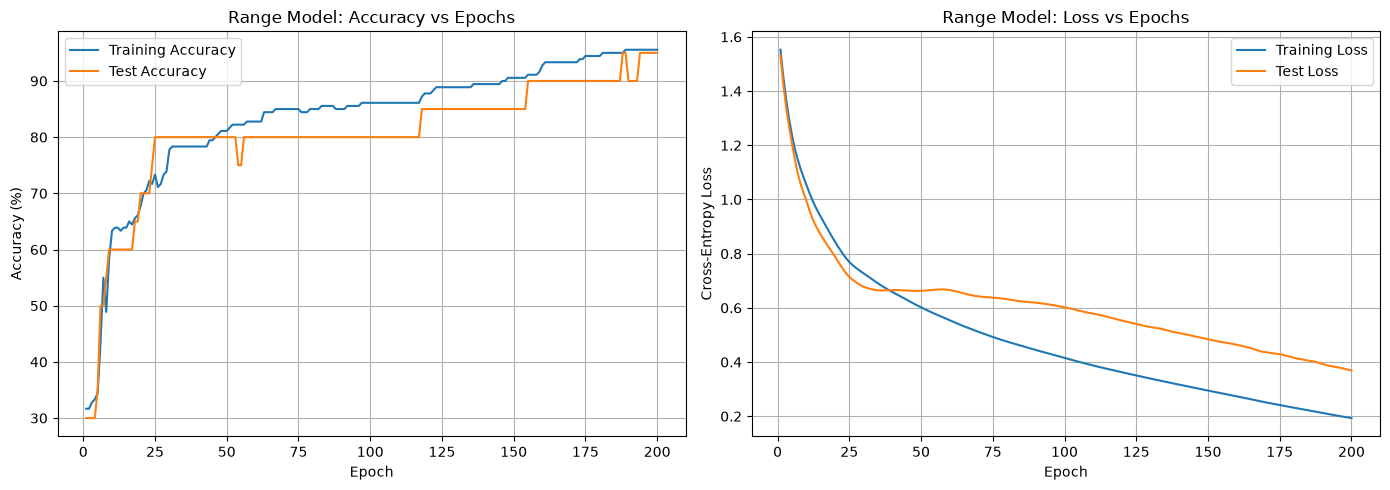

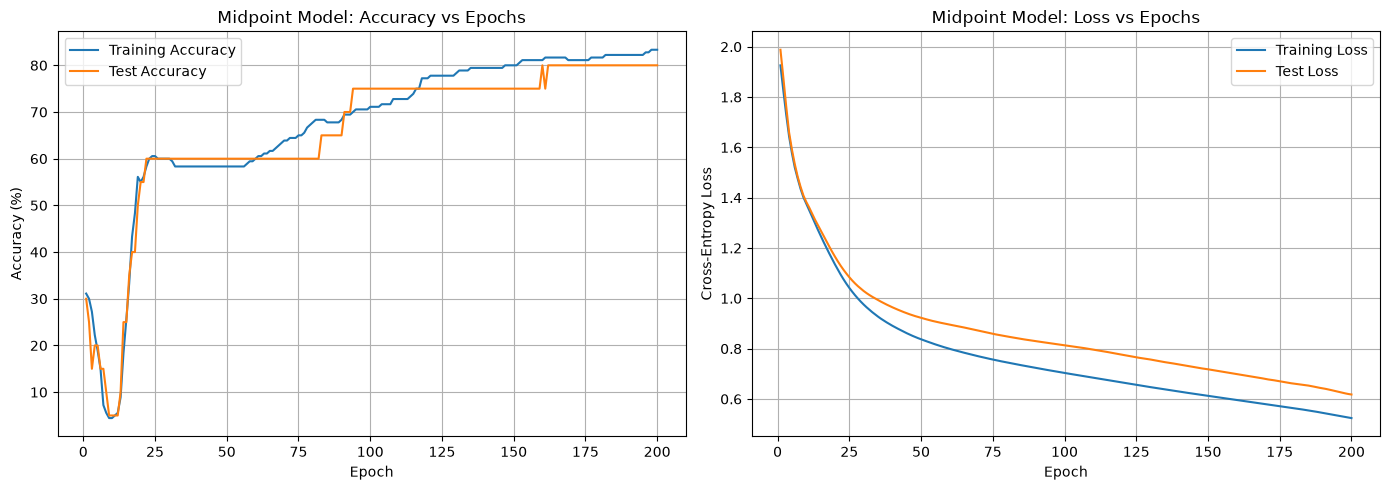

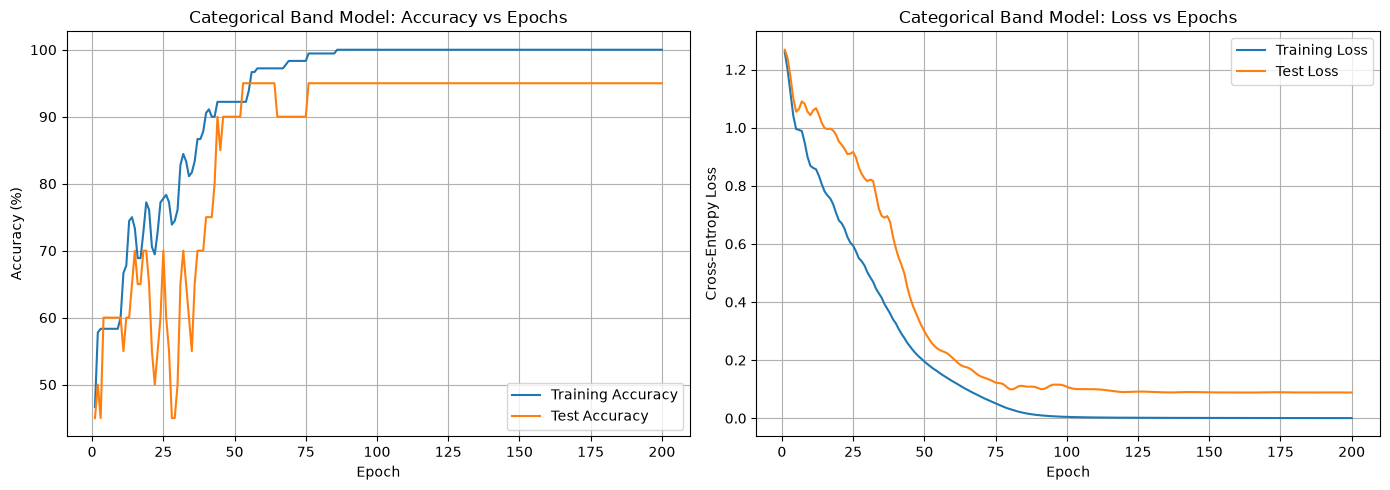

In [82]:
plot_training_history(history_range, "Range Model")
plot_training_history(history_mid, "Midpoint Model")
plot_training_history(history_band, "Categorical Band Model")

Generates confusion matrices for each trained model and prints their accuracy.

This is the final evaluation step for the notebook, showing how well each model classifies the test data across the degradation classes.


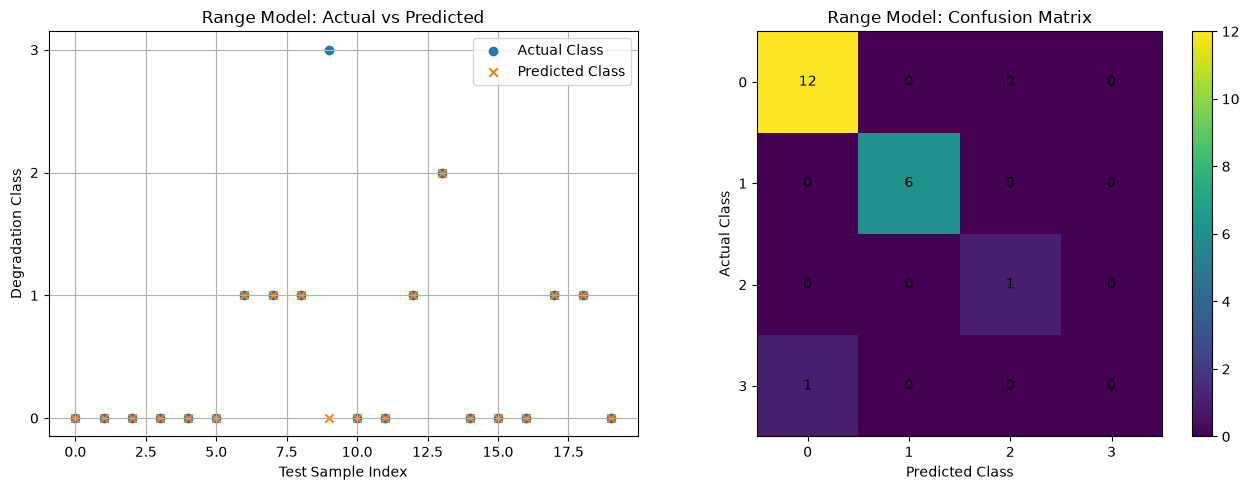

Test accuracy: 95.00%


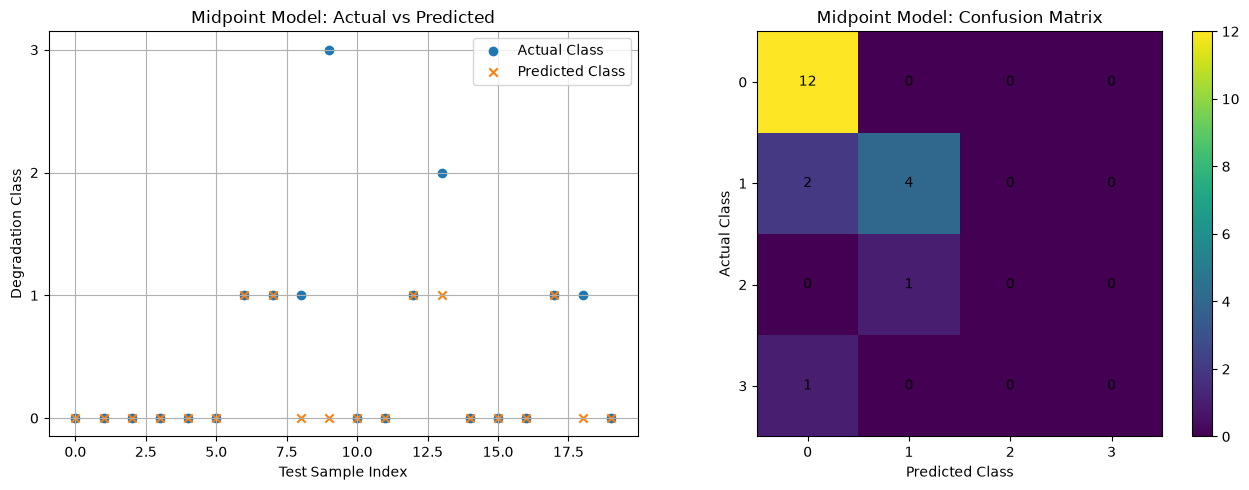

Test accuracy: 80.00%


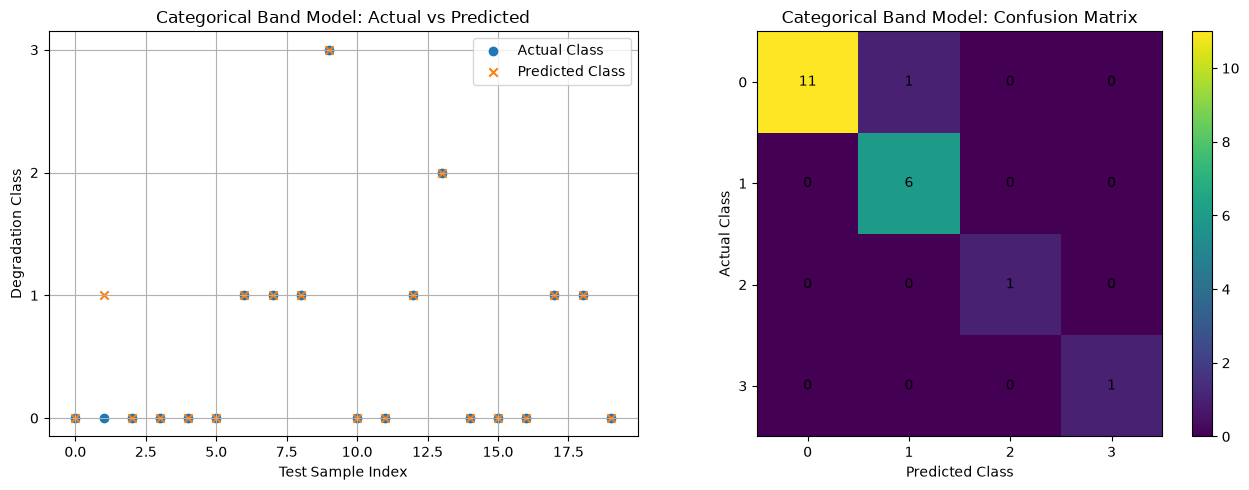

Test accuracy: 95.00%


In [85]:
# Confusion matrix for the Range-Prediction Model
plot_predictions(
    model_range, X_range_test_tensor,
    y_range_test_tensor, "Range Model"
)

# Confusion matrix for the Midpoint-Prediction Model
plot_predictions(
    model_mid, X_mid_test_tensor,
    y_mid_test_tensor, "Midpoint Model"
)

# Confusion matrix for the Categorical-Band Model
plot_predictions(
    model_band, X_band_test_tensor,
    y_band_test_tensor, "Categorical Band Model"
)